# Notebook 3 — Model Training & Evaluation
XGBoost credit risk classifier with SHAP explainability

In [1]:
import sys, os
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import shap
import joblib
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, f1_score, classification_report,
    RocCurveDisplay, ConfusionMatrixDisplay, precision_recall_curve
)
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

## 1. Load Preprocessed Data

In [2]:
from preprocess import preprocess, FEATURES

ENGINEERED = ['income_to_loan_ratio', 'credit_utilization_risk', 'monthly_debt_burden', 'fico_range']
ALL_FEATURES = FEATURES + ENGINEERED

CSV_PATH = '../accepted_2007_to_2018Q4.csv'

df = preprocess(CSV_PATH, sample_size=200_000)
print(f'Shape: {df.shape}  |  Default rate: {df["target"].mean():.2%}')

Shape: (199816, 30)  |  Default rate: 19.86%


## 2. Train / Test Split

In [3]:
X = df[ALL_FEATURES]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos_weight = neg / pos

print(f'Train: {len(X_train):,}  |  Test: {len(X_test):,}')
print(f'Train default rate   : {y_train.mean():.2%}')
print(f'scale_pos_weight     : {scale_pos_weight:.2f}')

Train: 159,852  |  Test: 39,964
Train default rate   : 19.86%
scale_pos_weight     : 4.03


## 3. Train XGBoost

In [4]:
model = XGBClassifier(
    n_estimators=1000,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=scale_pos_weight,
    eval_metric='auc',
    early_stopping_rounds=30,
    random_state=42,
    device='cpu',
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50
)

print(f'\nBest iteration: {model.best_iteration}')

[0]	validation_0-auc:0.70228
[50]	validation_0-auc:0.71727
[100]	validation_0-auc:0.72066
[150]	validation_0-auc:0.72215
[200]	validation_0-auc:0.72249
[250]	validation_0-auc:0.72274
[300]	validation_0-auc:0.72289
[333]	validation_0-auc:0.72260

Best iteration: 303


## 4. Find Optimal Threshold

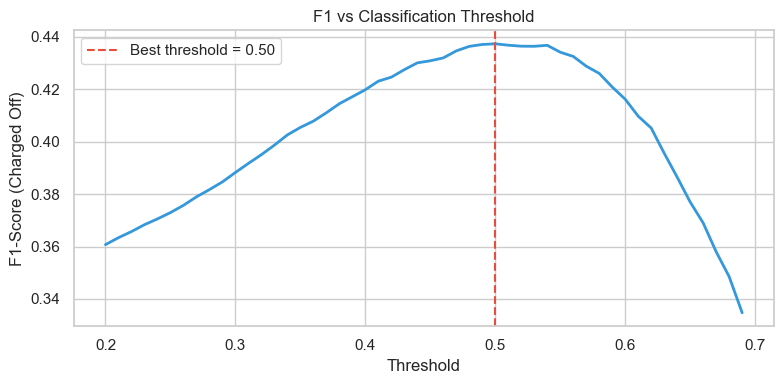

Optimal threshold : 0.50
Best F1-Score     : 0.4373


In [5]:
y_proba = model.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.20, 0.70, 0.01)
f1_scores  = [f1_score(y_test, (y_proba >= t).astype(int)) for t in thresholds]

best_thresh = thresholds[np.argmax(f1_scores)]
best_f1     = max(f1_scores)

plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores, color='#3498db', lw=2)
plt.axvline(best_thresh, color='#e74c3c', ls='--', label=f'Best threshold = {best_thresh:.2f}')
plt.xlabel('Threshold')
plt.ylabel('F1-Score (Charged Off)')
plt.title('F1 vs Classification Threshold')
plt.legend()
plt.tight_layout()
plt.show()

print(f'Optimal threshold : {best_thresh:.2f}')
print(f'Best F1-Score     : {best_f1:.4f}')

## 5. Evaluation Metrics

In [6]:
y_pred = (y_proba >= best_thresh).astype(int)

auc = roc_auc_score(y_test, y_proba)
f1  = f1_score(y_test, y_pred)

print(f'AUC-ROC  : {auc:.4f}')
print(f'F1-Score : {f1:.4f}')
print()
print(classification_report(y_test, y_pred, target_names=['Fully Paid','Charged Off']))

AUC-ROC  : 0.7229
F1-Score : 0.4373

              precision    recall  f1-score   support

  Fully Paid       0.89      0.66      0.76     32026
 Charged Off       0.33      0.66      0.44      7938

    accuracy                           0.66     39964
   macro avg       0.61      0.66      0.60     39964
weighted avg       0.78      0.66      0.70     39964



## 6. ROC Curve & Confusion Matrix

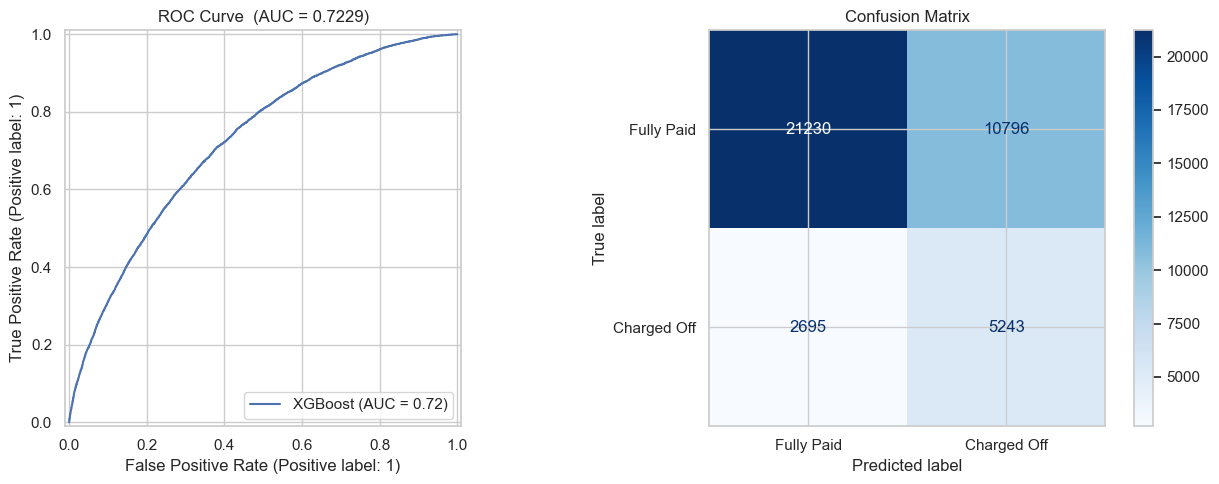

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0], name='XGBoost')
axes[0].set_title(f'ROC Curve  (AUC = {auc:.4f})')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, ax=axes[1],
    display_labels=['Fully Paid','Charged Off'],
    cmap='Blues'
)
axes[1].set_title('Confusion Matrix')

plt.tight_layout()
plt.show()

## 7. Precision-Recall Curve

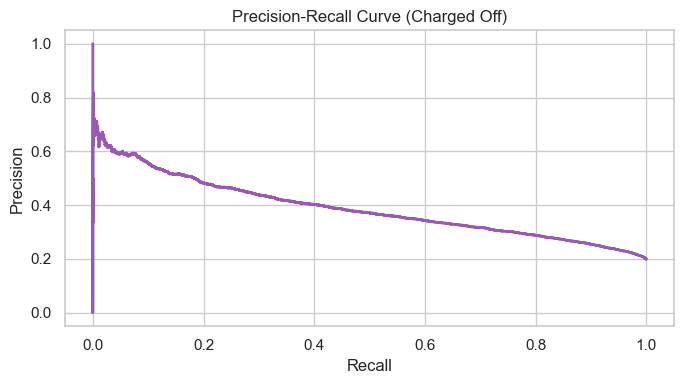

In [8]:
precision, recall, pr_thresh = precision_recall_curve(y_test, y_proba)

plt.figure(figsize=(7, 4))
plt.plot(recall, precision, color='#9b59b6', lw=2)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Charged Off)')
plt.tight_layout()
plt.show()

## 8. Feature Importance (XGBoost gain)

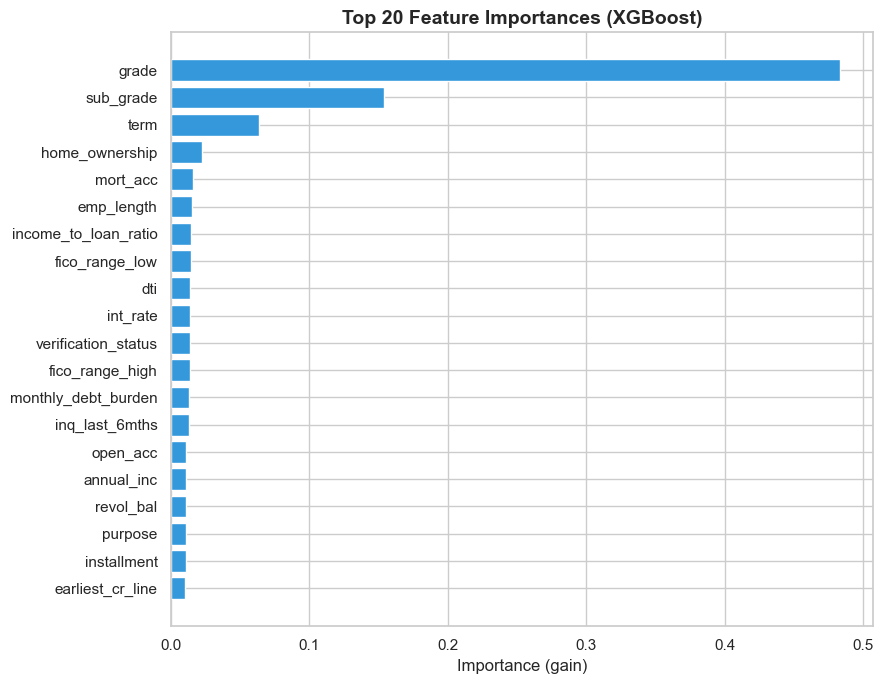

In [9]:
importance = pd.Series(model.feature_importances_, index=ALL_FEATURES)
importance = importance.sort_values(ascending=True).tail(20)

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(importance.index, importance.values, color='#3498db', edgecolor='white')
ax.set_xlabel('Importance (gain)', fontsize=12)
ax.set_title('Top 20 Feature Importances (XGBoost)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 9. SHAP Summary Plot

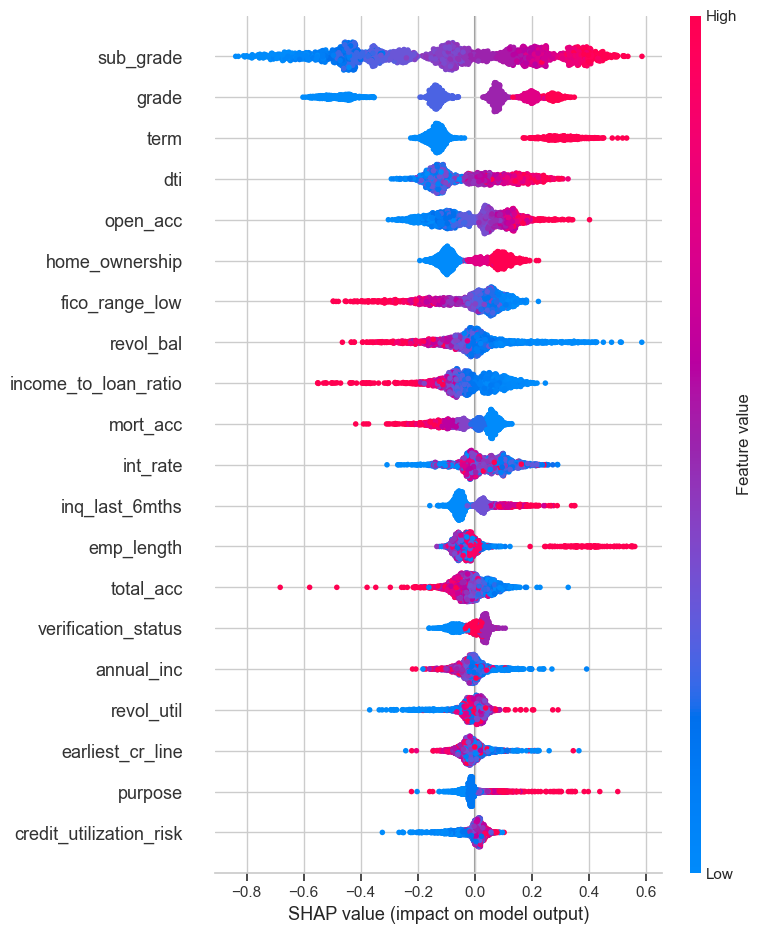

In [10]:
explainer  = shap.TreeExplainer(model)

# Use a 2000-row subsample for speed
X_shap = X_test.sample(2000, random_state=42)
shap_values = explainer.shap_values(X_shap)

plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_shap, feature_names=ALL_FEATURES, show=False)
plt.tight_layout()
plt.show()

## 10. SHAP Waterfall — Single Prediction

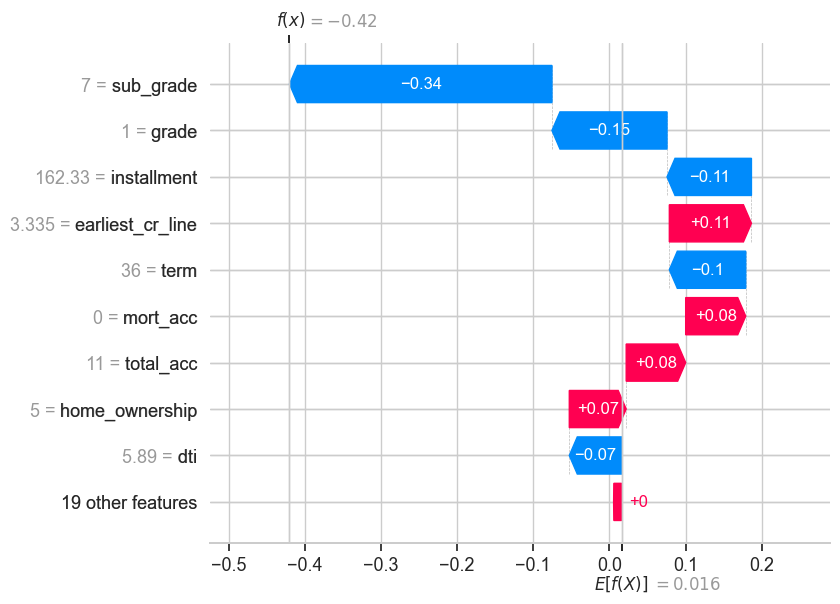

Predicted probability : 39.6%
Actual label          : Fully Paid


In [11]:
idx = 0  # change this to inspect a different test sample
sample = X_test.iloc[[idx]]
sv     = explainer.shap_values(sample)

explanation = shap.Explanation(
    values       = sv[0],
    base_values  = explainer.expected_value,
    data         = sample.iloc[0],
    feature_names= ALL_FEATURES
)

shap.plots.waterfall(explanation)

prob   = model.predict_proba(sample)[0][1]
actual = y_test.iloc[idx]
print(f'Predicted probability : {prob:.1%}')
print(f'Actual label          : {"Charged Off" if actual else "Fully Paid"}')

## 11. SHAP Bar — Global Feature Importance

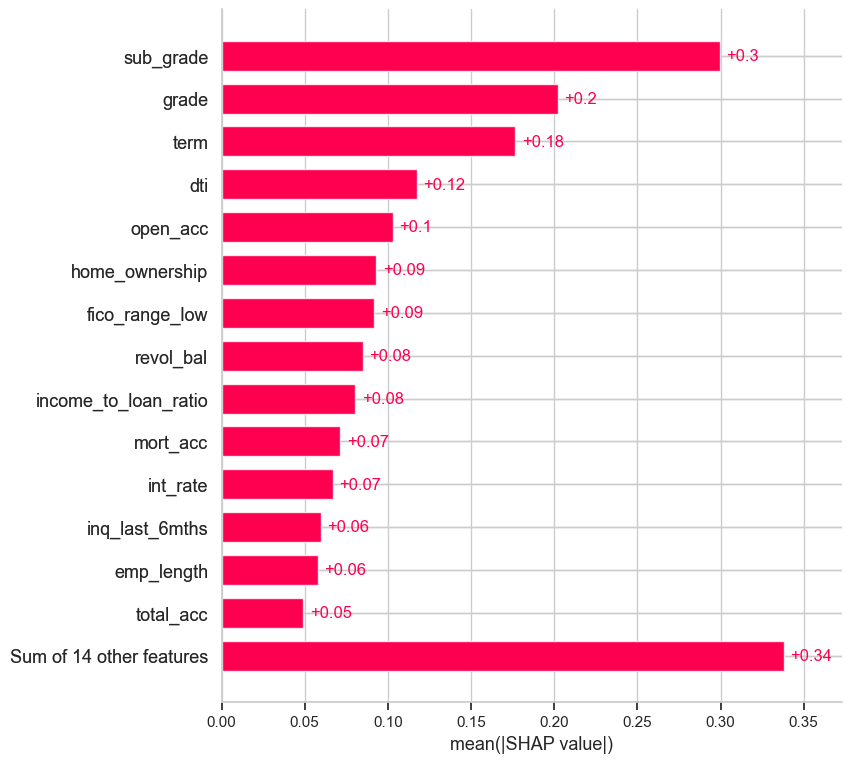

In [12]:
shap_exp = shap.Explanation(
    values       = shap_values,
    base_values  = explainer.expected_value,
    data         = X_shap.values,
    feature_names= ALL_FEATURES
)
shap.plots.bar(shap_exp, max_display=15)

## 12. Save Model

In [13]:
from preprocess import label_encoders

os.makedirs('../models', exist_ok=True)
MODEL_PATH = '../models/credit_model.pkl'

joblib.dump({
    'model'         : model,
    'features'      : ALL_FEATURES,
    'label_encoders': label_encoders,
    'threshold'     : float(best_thresh),
}, MODEL_PATH)

print(f'Model saved → {MODEL_PATH}')
print(f'  AUC-ROC  : {auc:.4f}')
print(f'  F1-Score : {f1:.4f}')
print(f'  Threshold: {best_thresh:.2f}')

Model saved → ../models/credit_model.pkl
  AUC-ROC  : 0.7229
  F1-Score : 0.4373
  Threshold: 0.50
